In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import pickle

# --- Custom imports ---
from Helpers import *   # Contains utility functions for data processing and plotting

# Configure matplotlib for consistent plots
plt.style.use("seaborn-v0_8-whitegrid")

In [3]:
def load_data(file_path):
    """
    Loads a two-column Parquet file and converts it back into a Python dictionary.
    """
    # 1. Read the Parquet file into a DataFrame
    df = pd.read_parquet(file_path)
    
    # 2. Zip the 'key' and 'value' columns together and convert to a dict
    return dict(zip(df['key'], df['value']))

In [4]:
# --- Load data files ---
ROOT_PATH = "/data/pgangwar/vaccinescout/data/"
DATA_PATH = ROOT_PATH +"final_df.parquet"

final_df = pd.read_parquet(DATA_PATH)

parent_node = pd.read_csv(ROOT_PATH + "parent_node.csv")

all_mut_data = pd.read_parquet(ROOT_PATH +'all_nodes_spike_2025-09-01_branch.parquet') 

dates_df = pd.read_csv(ROOT_PATH + 'chronumental_dates_gisaidAndPublic.2025-09-01.metadata.tsv', sep='\t')

ver = 'Jan_4_24'

pyro_df = pd.read_pickle(ROOT_PATH + f'pyro_ver/{ver}/PyroSpike.pkl')

In [5]:
# --- Preprocess Date Data ---
dates_df['predicted_date'] = pd.to_datetime(dates_df['predicted_date'])

dates_df['predicted_date'] = dates_df['predicted_date'].dt.date

dates_df['predicted_date'] = pd.to_datetime(dates_df['predicted_date'])

dates_df = dates_df.rename(columns={'strain': 'node_id'})

In [6]:
# --- Define cutoff date ---
cutoff_date = "2022-07-01"

d = 30

# --- Split dataframe into circulating and future segments ---
current_df, future_df = split_circulating_and_future(
    final_df,
    cutoff_date_str=cutoff_date,
    left_buffer_days=4,
    right_buffer_days=4,
    circulation_months=None,
    circulation_days=d,
    future_months=12,
    future_days=None
)

# --- Define windows for slicing future data ---
disjoint_windows = ['3M_1', '3M_2', '3M_3', '3M_4']

# --- Perform slicing ---
disjoint_slices = slice_by_disjoint_windows(future_df, disjoint_windows)

# --- Combine slices into one dictionary ---
future_slices = disjoint_slices

# --- Summary output ---
# print(f"Cumulative slices: {list(cumulative_slices.keys())}")
print(f"Disjoint slices: {list(disjoint_slices.keys())}")
print(f"Total future slices stored: {len(future_slices)}")

Disjoint slices: ['3M_1', '3M_2', '3M_3', '3M_4']
Total future slices stored: 4


Processing Nodes around Cutoff Date

In [7]:
# --- Filter Nodes around cutoff date ---
filtered_df = dates_df[dates_df['predicted_date'] < cutoff_date]


filtered_df = filtered_df[filtered_df['node_id'].str.contains('node_')]


nodes_before_cutoff = set(filtered_df['node_id'])

In [8]:
# --- Create Lookup Dictionaries ---
parent_node_clean = parent_node.dropna().drop_duplicates(subset=["node"])

parent_lookup = dict(zip(parent_node_clean["node"], parent_node_clean["parent_node"]))

mutations_lookup = dict(zip(all_mut_data['sample_id'], all_mut_data['aa_mutations']))

fitness_lookup = dict(zip(pyro_df['mutation'], pyro_df['R / R_A']))

In [9]:
# --- Apply functions to future data ---
for key, df in future_slices.items():
    df = df.copy()

    # Existing computations
    df["node_path"] = df["Sample_ID"].apply(lambda x: build_node_path(x, parent_lookup))
    df["anchor_remainder"] = df["node_path"].apply(
        lambda path: find_anchor_remainder_reverse(path, nodes_before_cutoff)
    )
    remainder_muts = df["anchor_remainder"].apply(
        lambda ar: get_mutations_from_remainder(ar, mutations_lookup)
    )

    mut_lengths = remainder_muts.str.len()
    mask = mut_lengths > 0
    df = df[mask].copy()

    df["mutations_in_remainder"] = remainder_muts[mask]
    df["total_mutations_in_remainder"] = mut_lengths[mask]
    
    future_slices[key] = df

In [10]:
def get_fitness_list(mutation_list):
    return [fitness_lookup[mut] for mut in mutation_list if mut in fitness_lookup]

for key, df in future_slices.items():
    df['mutations_in_remainder'] = df['mutations_in_remainder'].apply(
        lambda lst: [mut for mut in lst if mut in fitness_lookup]
    )  
    
    df['fitness_in_remainder'] = df['mutations_in_remainder'].apply(get_fitness_list)
    # .str.len() checks the length of the list in each row. We only keep lengths > 0.
    df = df[df['mutations_in_remainder'].str.len() > 0].copy()
    future_slices[key] = df

In [12]:
slice_stats = {}

for key, df in future_slices.items():

    all_mutations = [m for lst in df['mutations_in_remainder'] for m in lst]
    
    slice_stats[key] = {
        "total_mutations": len(all_mutations),
        "unique_mutations": len(set(all_mutations)),
        "total_sequences": len(df)  
    }

Process Mutation Counts

In [13]:
# --- Compute fitness frequency distributions ---
fitness_freqs = {}

for key, df in future_slices.items():
    # Flatten all fitness scores across tips seen after the cutoff
    all_fitness = [f for lst in df['fitness_in_remainder'] for f in lst if f is not None]
    
    # Count frequency of each score
    freq_df = pd.Series(all_fitness).value_counts().reset_index()
    freq_df.columns = ["fitness_score", "frequency"]
    
    # Store in dict
    fitness_freqs[key] = freq_df

fitness_freqs_normalized = {}

for key, freq_df in fitness_freqs.items():
    total_mutations = slice_stats[key]["total_mutations"]

    # add a normalized percentage column
    freq_df = freq_df.copy()
    freq_df["percent"] = (freq_df["frequency"] / total_mutations) * 100

    fitness_freqs_normalized[key] = freq_df

In [15]:
#################REMOVE

#for key, freq_df in fitness_freqs_normalized.items():
#    # Sort the dataframe by the 'percent' column in descending order
#    sorted_df = freq_df.sort_values(by="frequency", ascending=False)
#    total_percent = sorted_df["percent"].sum()
#    print(f"========== Slice: {key} | Total Percent: {total_percent:.2f}% ==========") 
#    print(sorted_df.head(5))
#    print("\n")

mut_freqs = {}
for key, df in future_slices.items():
    all_mutations = [f for lst in df['mutations_in_remainder'] for f in lst if f is not None]
    total_raw_occurrences = len(all_mutations)
    
    # Count frequency of each score
    mut_freq_df = pd.Series(all_mutations).value_counts().reset_index()
    mut_freq_df.columns = ["mutation", "frequency"]
    mut_freq_df = mut_freq_df.sort_values(by="frequency", ascending=False)
    mut_freq_df["percent"] = (mut_freq_df["frequency"] / total_raw_occurrences) * 100

    mut_freq_df["in_lookup"] = mut_freq_df["mutation"].isin(fitness_lookup)
    mut_freq_df["fitness_score"] = mut_freq_df["mutation"].map(fitness_lookup)
    mut_freq_df = mut_freq_df.sort_values(by="fitness_score", ascending=False)
    
    unique_muts_count = len(mut_freq_df)
    unique_known_count = mut_freq_df["in_lookup"].sum()
    pct_unique_known = (unique_known_count / unique_muts_count) * 100 if unique_muts_count > 0 else 0

    recurrent_mask = mut_freq_df["frequency"] > 1
    count_greater_than_one = recurrent_mask.sum()
    recurrent_known_count = mut_freq_df[recurrent_mask]["in_lookup"].sum()
    pct_recurrent_known = (recurrent_known_count / count_greater_than_one) * 100 if count_greater_than_one > 0 else 0

    print(f"========== Slice: {key} ==========")
    #print(f"Raw occurrences:        {total_raw_occurrences}")
    print(f"Total UNIQUE mutations: {unique_muts_count} ({pct_unique_known:.2f}% found in Fitness Table)")
    print(f"UNIQUE mutations with freq > 1:   {count_greater_than_one} ({pct_recurrent_known:.2f}% found in Fitness Table)")
    print("-" * 40)
    
    print(mut_freq_df.head(3))
    print("\n")

    #mut_freqs[key] = mut_freq_df
##################

========== Slice: 3M_1 ==========
Total UNIQUE mutations: 714 (100.00% found in Fitness Table)
UNIQUE mutations with freq > 1:   689 (100.00% found in Fitness Table)
----------------------------------------
    mutation  frequency   percent  in_lookup  fitness_score
691  S:D614G          1  0.002569       True        1.18443
142  S:D796Y         91  0.233819       True        1.11575
434  S:N679K         15  0.038542       True        1.11159


========== Slice: 3M_2 ==========
Total UNIQUE mutations: 717 (100.00% found in Fitness Table)
UNIQUE mutations with freq > 1:   698 (100.00% found in Fitness Table)
----------------------------------------
    mutation  frequency   percent  in_lookup  fitness_score
130  S:D796Y        125  0.235538       True        1.11575
379  S:N679K         29  0.054645       True        1.11159
711  S:H655Y          1  0.001884       True        1.09192


========== Slice: 3M_3 ==========
Total UNIQUE mutations: 713 (100.00% found in Fitness Table)
UNIQUE 

In [21]:
import numpy as np

bin_edges = np.arange(0.9, 1.14 + 0.01, 0.0001)

bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

binned_results = {}

for key, df in fitness_freqs_normalized.items():
    # sum percent in each bin
    binned, _ = np.histogram(
        df["fitness_score"],
        bins=bin_edges,
        weights=df["percent"]  # sum of percentages
    )

    binned_results[key] = pd.DataFrame({
        "bin_center": bin_centers,
        "percent_sum": binned
    })

Plot Results

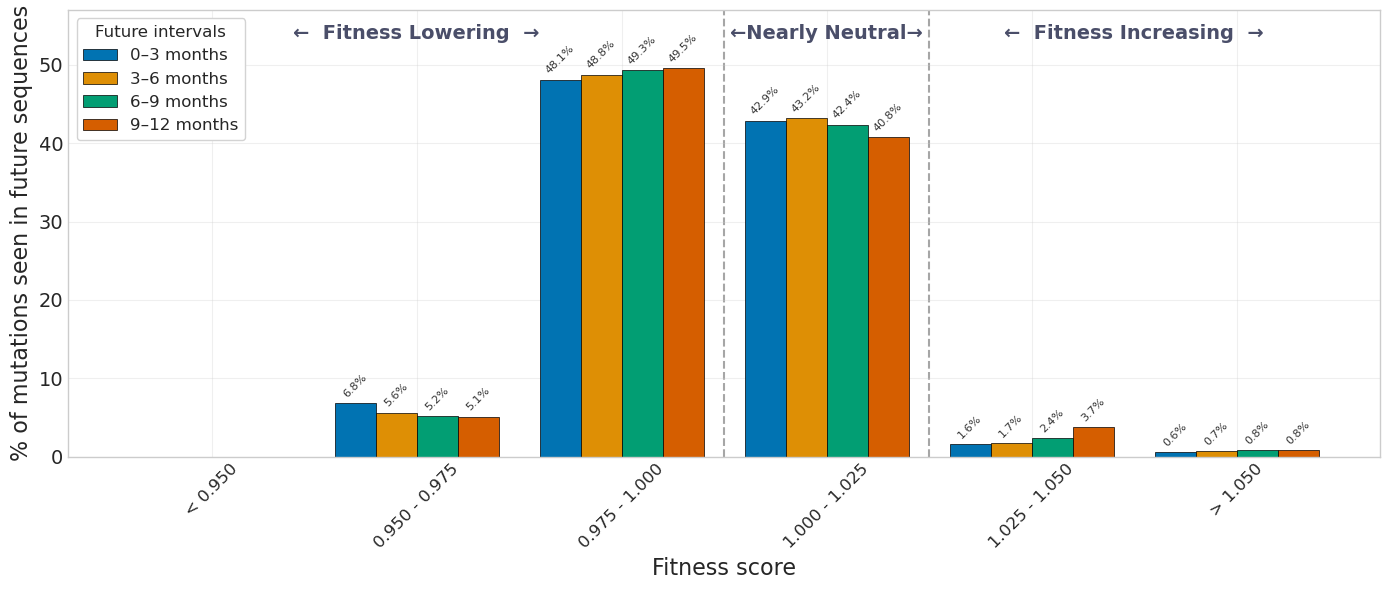

In [66]:
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.ndimage import gaussian_filter1d

slices_to_plot = ["3M_1", "3M_2", "3M_3", "3M_4"]  # fixed order
legend_labels = {
    "3M_1": "0–3 months",
    "3M_2": "3–6 months",
    "3M_3": "6–9 months",
    "3M_4": "9–12 months"
}

# seaborn colorblind palette
palette = sns.color_palette("colorblind", n_colors=len(slices_to_plot))
slice_colors = {key: palette[i] for i, key in enumerate(slices_to_plot)}

plt.figure(figsize=(14, 6))

total_slices = len(slices_to_plot)
target_bin_size = 0.025
group_width = target_bin_size * 0.8
bar_width = group_width / total_slices

for i, key in enumerate(slices_to_plot):
    df = binned_results[key].copy()
    df["coarse_bin"] = (df["bin_center"] // target_bin_size) * target_bin_size + (target_bin_size / 2)

    # Force edge data into specific "underflow" and "overflow" bins
    # We use 0.9375 and 1.0625 as they maintain the perfect 0.025 spacing on the x-axis
    df.loc[df["bin_center"] < 0.95, "coarse_bin"] = 0.9375
    df.loc[df["bin_center"] >= 1.05, "coarse_bin"] = 1.0625
    
    df_grouped = df.groupby("coarse_bin", as_index=False)["percent_sum"].sum()  
    x = df_grouped["coarse_bin"].to_numpy()
    y = df_grouped["percent_sum"].to_numpy()

    offset = (i - (total_slices - 1) / 2) * bar_width

    plt.bar(
        x + offset, y, 
        width=bar_width, 
        color=slice_colors[key], 
        label=legend_labels[key], 
        alpha=1.0,           
        edgecolor='black',   
        linewidth=0.5
    )

    for val_x, val_y in zip(x + offset, y):
        if val_y > 0.5:  # Only trigger if the percentage is greater than x%
            plt.text(
                val_x, val_y + 0.5,      
                f"{val_y:.1f}%",        
                ha='center', va='bottom', 
                fontsize=8,               
                rotation=45,             
                color='#333333'           
            )


plt.xlabel("Fitness score", fontsize=16)
plt.ylabel("% of mutations seen in future sequences", fontsize=16)
# plt.title("Fitness distribution per slice (tips-normalized, KDE only)", fontsize=16)
leg = plt.legend(title="Future intervals", fontsize=12, title_fontsize=12, 
                 frameon=True, facecolor='white', edgecolor='lightgray', framealpha=1.0)
leg.set_zorder(100)

plt.xlim(0.92, 1.08)
clean_ticks = np.arange(0.9375, 1.0626, 0.025)
tick_labels = []
for val in clean_ticks:
    if val < 0.95: 
        tick_labels.append("< 0.950")
    elif val > 1.05: 
        tick_labels.append("> 1.050")
    else:
        # Standard formatting for the middle ranges
        tick_labels.append(f"{val - 0.0125:.3f} - {val + 0.0125:.3f}")

plt.xticks(ticks=clean_ticks, labels=tick_labels, rotation=45, fontsize=12)
plt.gca().ticklabel_format(axis='y', useOffset=False, style='plain')

plt.yticks(fontsize=14)
plt.grid(alpha=0.3)

plt.ylim(0, 57)
plt.axvline(x=1.000, color='gray', linestyle='--', linewidth=1.5, alpha=0.7, zorder=0)
plt.axvline(x=1.025, color='gray', linestyle='--', linewidth=1.5, alpha=0.7, zorder=0)

plt.text(
    x=0.9625, y=54, 
    s="←  Fitness Lowering  →", 
    ha='center', va='center', 
    fontsize=14, fontweight='bold', color='#4a4e69'
)
plt.text(
    x=1.0125, y=54, 
    s="←Nearly Neutral→", 
    ha='center', va='center', 
    fontsize=14, fontweight='bold', color='#4a4e69'
)
plt.text(
    x=1.050, y=54, 
    s="←  Fitness Increasing  →", 
    ha='center', va='center', 
    fontsize=14, fontweight='bold', color='#4a4e69'
)

plt.tight_layout()
# plt.savefig("/data/sukhanna/MPP/ver_2/ver_2A/Final_Images/new_mutation_fitness.svg", format='svg')
plt.show()